# Simulación de la disipación energética de algoritmos mediante el principio de Landauer


**Integrantes:**

-Gerónimo Naranjo 202415840

-Manuela León 202520087

-David Reyes Herrera  202521496


## 1. Introducción

### 1.1. Contextualización

El ordenamiento permite estudiar cómo distintas estrategias transforman la misma
entrada. Además de comparar sus requisitos de tiempo y memoria, se puede preguntar
cuánta información pierden durante la transformación. Demaine et al. (2016)
proponen un modelo para estudiar ese costo a partir del principio de Landauer.
Este ensayo aplica sus ideas a cuatro algoritmos de ordenamiento por comparación.

### 1.2. Pregunta, objetivos e hipótesis

¿Cómo varía la energía mínima estimada al ordenar una permutación aleatoria con
Insertion Sort, Merge Sort, Quick Sort o Heap Sort, y qué operaciones explican
las diferencias? El objetivo es simular los cuatro procedimientos bajo una misma
regla de contabilización, estimar sus medias sobre entradas emparejadas y
contrastarlas con referencias analíticas e informacionales.

Se espera que Insertion Sort se separe de los otros algoritmos a medida que crece
la entrada. Para Merge Sort, Quick Sort y Heap Sort se espera un crecimiento
promedio compatible con $n\log_2 n$ bajo el muestreo elegido. La posición relativa
de esas tres curvas depende de cuántas comparaciones hace cada implementación.

### 1.3. Alcance

El experimento usa permutaciones uniformes de claves distintas, palabras de 64
bits y una temperatura fija de 300 K. La simulación compara la disipación mínima
asociada con el conteo del modelo. Los resultados describen esas entradas y estas
implementaciones. El consumo eléctrico de un procesador requeriría mediciones
físicas y depende de factores como la arquitectura, la memoria y la frecuencia.

## 2. Modelo físico: principio de Landauer

### 2.1. Fundamentación física e implementación

Sea $H=-\sum_i p_i\log_2 p_i$ la entropía de la información, medida en bits. Al
reiniciar un bit equiprobable a un estado fijo, $H$ pasa de uno a cero. Para ese
reinicio ideal en contacto con un baño térmico a temperatura $T$, la entropía
exportada al entorno satisface $\Delta S_{\mathrm{entorno}}\geq k_B\ln 2$.
En el límite isotérmico ideal, $Q=T\Delta S_{\mathrm{entorno}}$. El calor mínimo
por bit es, por tanto, $q_L=k_B T\ln 2$. Para $B$ bits contabilizados, se usa

$$
E(B)=Bq_L=B k_B T\ln 2.
$$

Aquí $k_B=1.380649\times10^{-23}\,\mathrm{J/K}$ es la constante de Boltzmann,
$T=300\,\mathrm{K}$ es la temperatura del baño, $q_L$ se expresa en J/bit y $E$
en J. La celda calcula el factor de conversión. El bit equiprobable ilustra
el límite físico; la máquina aplica un bit contable por resultado descartado
aunque la distribución concreta de esos resultados pueda estar sesgada.

In [22]:
# 2.1. Implementación del modelo físico
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

k_B = 1.380649e-23  # J/K
T = 300.0  # K
q_L = k_B * T * math.log(2)  # J/bit


def calculate_energy(bits):
    """Convierte los bits contabilizados en energía de Landauer.

    Args:
        bits: Cantidad de bits destruidos, como escalar o serie.

    Returns:
        Energía en joules, con la forma del argumento.
    """
    return bits * q_L


print(f"Energía de Landauer por bit a {T:g} K: {q_L:.6e} J/bit")


Energía de Landauer por bit a 300 K: 2.870979e-21 J/bit


**Interpretación.** A 300 K, la conversión da $q_L\approx2.871\times10^{-21}$ J/bit.
A temperatura fija, duplicar los bits contabilizados duplica la energía estimada.
Este valor corresponde al límite ideal asociado al borrado.

## 3. Modelo computacional: Energy Word RAM

### 3.1. Fundamentación e implementación de Energy Word RAM

La clase representa un arreglo en palabras de $w$ bits, con un bloque auxiliar
opcional inicializado en cero. Su estado distingue comparaciones, operaciones
primitivas y bits destruidos. Las reglas aplicadas son las siguientes.

| Operación | Efecto en la memoria | Bits destruidos |
|---|---|---:|
| SET | Copia el origen sobre un destino distinto y pierde el contenido anterior | $w$ |
| SWAP | Intercambia las palabras y conserva los dos valores | 0 |
| COPY | Copia a una dirección distinta cuyo contenido inicial es cero | 0 |
| COMPARE y descarte | Compara las claves y contabiliza el descarte del resultado booleano | 1 |

Una comparación puede producir el resultado conservando los operandos. La
irreversibilidad que se carga aquí corresponde al descarte del resultado y se
registra al llamar a "compare"  como una operación adicional. SET aplica el
costo de una palabra según la convención del modelo. SWAP se invierte repitiendo
el intercambio y COPY puede invertirse si se conserva el origen y se conoce el
estado inicial del destino. Las direcciones, los índices, los contadores y la
pila de Quick Sort quedan fuera del conteo energético explícito.

In [23]:
# 3.1. Implementación de la máquina
class EnergyWordRAM:
    """Simula memoria de palabras y contabiliza el descarte de información."""

    def __init__(self, data, word_size=64, auxiliary_size=0):
        """Inicializa la memoria y los contadores de operaciones.

        Args:
            data: Claves que se copian al bloque inicial.
            word_size: Número de bits por palabra.
            auxiliary_size: Cantidad de palabras auxiliares en cero.
        """
        if word_size <= 0 or auxiliary_size < 0:
            raise ValueError("Parámetros de memoria inválidos")
        self.word_size = word_size
        self.n = len(data)
        self.memory = [int(x) for x in data] + [0] * auxiliary_size
        if any(x < 0 or x >= 2**word_size for x in self.memory):
            raise ValueError("Valor fuera del rango de una palabra")
        self.bits_destroyed = 0
        self.operations = 0
        self.comparisons = 0

    def set(self, a, b):
        """Sobrescribe el destino y contabiliza la pérdida de una palabra.

        Args:
            a: Dirección de destino.
            b: Dirección de origen, distinta de a.
        """
        # SET(a,b): destino a, origen b.
        if a == b:
            raise ValueError("SET requiere direcciones distintas")
        self.memory[a] = self.memory[b]
        self.bits_destroyed += self.word_size
        self.operations += 1

    def swap(self, a, b):
        """Intercambia dos palabras sin contabilizar bits destruidos.

        Args:
            a: Primera dirección de memoria.
            b: Segunda dirección de memoria.
        """
        self.memory[a], self.memory[b] = self.memory[b], self.memory[a]
        self.operations += 1

    def copy(self, a, b):
        """Copia una palabra a una dirección vacía sin destruir bits.

        Args:
            a: Dirección de origen.
            b: Dirección de destino, distinta de a y con valor cero.
        """
        # COPY(a,b): origen a, destino b inicialmente vacío.
        if a == b or self.memory[b] != 0:
            raise ValueError("COPY requiere un destino distinto y vacío")
        self.memory[b] = self.memory[a]
        self.operations += 1

    def compare(self, a, b):
        """Compara dos palabras y contabiliza el descarte del resultado.

        Args:
            a: Dirección del operando izquierdo.
            b: Dirección del operando derecho.

        Returns:
            Verdadero si la palabra en a es menor o igual a la de b.
        """
        # COMPARE (0 bits) + descarte del resultado (1 bit).
        # Se contabiliza anticipadamente el descarte, tras el uso del booleano.
        self.comparisons += 1
        self.bits_destroyed += 1
        self.operations += 2
        return self.memory[a] <= self.memory[b]

    def get_bits(self):
        """Devuelve el total de bits destruidos."""
        return self.bits_destroyed

    def get_energy(self):
        """Devuelve la energía acumulada en joules."""
        return calculate_energy(self.bits_destroyed)

    def get_output(self):
        """Devuelve una lista con el bloque de datos, sin el auxiliar."""
        return self.memory[: self.n]

    def auxiliary_is_empty(self):
        """Indica si todas las palabras auxiliares valen cero."""
        return all(x == 0 for x in self.memory[self.n :])


### 3.2. Funcionamiento y verificación de la máquina

La traza empieza con dos palabras de datos y una auxiliar vacía. Los intercambios
y la copia comprueban que mover o duplicar información con las precondiciones del
modelo conserva el contador de bits. La sobrescritura y las dos comparaciones
permiten comprobar los incrementos exactos. Otra prueba repite cien veces la
comparación y verifica la conversión a joules. También se comprueba que COPY
rechace un destino ocupado.

La máquina separa así las modificaciones de memoria del conteo que alimenta la estimación de Landauer.

In [24]:
# 3.2. Ejemplo y verificación de la máquina
ram = EnergyWordRAM([5, 3], auxiliary_size=1)
trace = []


def record(operation):
    """Agrega el estado actual de la máquina a la traza.

    Args:
        operation: Nombre de la operación que acaba de ejecutarse.
    """
    trace.append(
        {
            "Operación": operation,
            "Memoria": ram.memory.copy(),
            "Bits acumulados": ram.get_bits(),
            "Energía (J)": ram.get_energy(),
        }
    )


record("Estado inicial")
ram.swap(0, 1)
assert ram.memory == [3, 5, 0] and ram.get_bits() == 0
record("SWAP(0, 1)")
ram.swap(0, 1)
assert ram.memory == [5, 3, 0] and ram.get_bits() == 0
record("SWAP(0, 1)")
ram.copy(0, 2)
assert ram.memory == [5, 3, 5] and ram.get_bits() == 0
record("COPY(0, 2)")
ram.set(0, 1)
assert ram.memory == [3, 3, 5] and ram.get_bits() == 64
record("SET(0, 1)")
assert ram.compare(0, 2) is True and ram.get_bits() == 65
record("COMPARE(0, 2) + descarte")
assert ram.compare(2, 0) is False and ram.get_bits() == 66
record("COMPARE(2, 0) + descarte")

ram_test = EnergyWordRAM([2, 1])
for _ in range(100):
    ram_test.compare(0, 1)
assert ram_test.get_bits() == ram_test.comparisons == 100
assert math.isclose(ram_test.get_energy(), 100 * q_L)

try:
    EnergyWordRAM([1, 2]).copy(0, 1)
except ValueError:
    pass
else:
    raise AssertionError("COPY permitió sobrescribir una palabra ocupada")

display(pd.DataFrame(trace))
print("Pruebas de operaciones superadas.")


,Operación,Memoria,Bits acumulados,Energía (J)
0,Estado inicial,"[5, 3, 0]",0,0.000000e+00
1,"SWAP(0, 1)","[3, 5, 0]",0,0.000000e+00
2,"SWAP(0, 1)","[5, 3, 0]",0,0.000000e+00
3,"COPY(0, 2)","[5, 3, 5]",0,0.000000e+00
4,"SET(0, 1)","[3, 3, 5]",64,1.837426e-19
5,"COMPARE(0, 2) + descarte","[3, 3, 5]",65,1.866136e-19
6,"COMPARE(2, 0) + descarte","[3, 3, 5]",66,1.894846e-19


Pruebas de operaciones superadas.


**Interpretación.** La traza permanece en cero después de los intercambios y de
COPY. SET eleva el total a 64 bits y las dos comparaciones lo llevan a 65 y 66.
El conteo separa así la cantidad de operaciones primitivas de la cantidad de
información cuyo descarte se carga al algoritmo.

## 4. Implementación de los algoritmos

### 4.1. Selección de algoritmos

Se comparan cuatro algoritmos de ordenamiento por comparación. Insertion Sort intercambia vecinos; Merge Sort fusiona bloques con memoria auxiliar; Quick Sort particiona alrededor de un pivote y Heap Sort extrae máximos de un montículo. Las cuatro implementaciones usan las mismas primitivas sobre los datos. `compare` devuelve si el primer valor es menor o igual que el segundo y contabiliza un bit al descartar el resultado. `swap` conserva ambos valores y contabiliza cero bits. Las cuatro rutinas ordenan mediante estas dos primitivas, de modo que su energía estimada es $E = C k_B T \ln 2$, donde $C$ es el número de comparaciones entre claves.

### 4.2. Insertion Sort

Se recorre el arreglo de izquierda a derecha y se desplaza cada elemento mediante intercambios adyacentes hasta que la porción recorrida queda ordenada.

In [25]:
# 4.2. Implementación de Insertion Sort
def insertion_sort(ram):
    """Ordena por inserción mediante intercambios adyacentes.

    Args:
        ram: Máquina con el bloque inicial de claves.

    Returns:
        Lista ordenada del bloque inicial.
    """
    compare = ram.compare
    swap = ram.swap
    for i in range(1, ram.n):
        j = i
        while j > 0:
            if compare(j - 1, j):
                break
            swap(j - 1, j)
            j -= 1
    return ram.get_output()


**Interpretación.** Cada comparación entre vecinos aporta un bit. Una entrada ordenada requiere $n-1$ comparaciones; la entrada invertida con claves distintas requiere $n(n-1)/2$. Los intercambios que desplazan cada elemento son reversibles en el modelo.

### 4.3. Merge Sort

Se fusionan bloques contiguos de tamaño creciente y se alternan los bloques de origen y destino. El destino empieza vacío y los intercambios dejan libre el origen para la siguiente pasada.

In [26]:
# 4.3. Implementación de Merge Sort
def merge_sort(ram):
    """Ordena mediante fusiones iterativas de bloques contiguos.

    Args:
        ram: Máquina con las claves y un bloque auxiliar vacío.

    Returns:
        Lista ordenada del bloque inicial.
    """
    n = ram.n
    if len(ram.memory) < 2 * n or not ram.auxiliary_is_empty():
        raise ValueError("Merge Sort requiere n palabras auxiliares vacías")

    compare = ram.compare
    swap = ram.swap
    source, destination = 0, n
    width = 1

    while width < n:
        for start in range(0, n, 2 * width):
            mid = min(start + width, n)
            end = min(start + 2 * width, n)
            i, j, k = start, mid, start

            while i < mid and j < end:
                if compare(source + i, source + j):
                    swap(source + i, destination + k)
                    i += 1
                else:
                    swap(source + j, destination + k)
                    j += 1
                k += 1

            while i < mid:
                swap(source + i, destination + k)
                i += 1
                k += 1

            while j < end:
                swap(source + j, destination + k)
                j += 1
                k += 1

        # El origen queda vacío y se reutiliza como destino.
        source, destination = destination, source
        width *= 2

    # El resultado queda en el bloque inicial, y el auxiliar queda vacío.
    if source != 0:
        for i in range(n):
            swap(source + i, i)
    return ram.get_output()


**Interpretación.** El costo se acumula mientras ambas mitades tienen elementos pendientes. Una vez agotada una mitad, los elementos restantes se trasladan mediante intercambios sin comparaciones entre claves. Al terminar se restaura el resultado al bloque inicial y el auxiliar queda vacío.

### 4.4. Quick Sort

Una pila de intervalos reemplaza la recursión. En cada intervalo se lleva el elemento central al extremo derecho y se particiona mediante intercambios, usando la comparación de la máquina para agrupar las claves menores o iguales al pivote. Mantener el pivote en una dirección permite comparar sin leer directamente su valor.

In [27]:
# 4.4. Implementación de Quick Sort
def quick_sort(ram):
    """Ordena con una pila de intervalos y pivote de posición central.

    Args:
        ram: Máquina con las claves que se van a particionar.

    Returns:
        Lista ordenada del bloque inicial.
    """
    pending = [(0, ram.n - 1)]
    while pending:
        start, end = pending.pop()
        if start >= end:
            continue

        middle = (start + end) // 2
        ram.swap(middle, end)
        position = start
        for index in range(start, end):
            if ram.compare(index, end):
                if position != index:
                    ram.swap(position, index)
                position += 1

        if position != end:
            ram.swap(position, end)
        pending.append((start, position - 1))
        pending.append((position + 1, end))

    return ram.get_output()


**Interpretación.** Una partición de longitud $m$ aporta $m-1$ bits, uno por cada comparación con el pivote. El costo total depende de los tamaños de los intervalos que quedan a ambos lados. Elegir la posición central determina la regla de selección y admite particiones desbalanceadas según las claves de entrada.

### 4.5. Heap Sort

Se construye un montículo máximo desde los últimos nodos internos. Después se intercambia la raíz con la última posición activa y se restaura el montículo en el prefijo restante. Se usa la comparación existente con los operandos en el orden necesario para detectar si el hijo supera al mayor candidato.

In [28]:
# 4.5. Implementación de Heap Sort
def heap_sort(ram):
    """Ordena construyendo un montículo máximo y extrayendo sus raíces.

    Args:
        ram: Máquina con el bloque inicial de claves.

    Returns:
        Lista ordenada del bloque inicial.
    """

    def sift_down(size, root):
        """Restaura la propiedad de montículo desde la raíz dada.

        Args:
            size: Cantidad de posiciones activas del montículo.
            root: Índice desde el que empieza el descenso.
        """
        while True:
            largest = root
            left = 2 * root + 1
            right = left + 1

            if left < size and not ram.compare(left, largest):
                largest = left
            if right < size and not ram.compare(right, largest):
                largest = right
            if largest == root:
                break

            ram.swap(root, largest)
            root = largest

    for root in range(ram.n // 2 - 1, -1, -1):
        sift_down(ram.n, root)

    for end in range(ram.n - 1, 0, -1):
        ram.swap(0, end)
        sift_down(end, 0)

    return ram.get_output()


**Interpretación.** Cada comparación con un hijo existente aporta un bit. Las comparaciones se acumulan tanto al construir el montículo como al restaurarlo tras cada extracción. Los intercambios de la raíz y los descensos conservan las claves y no añaden bits destruidos.

### 4.6. Pruebas de ordenamiento

Se crea una máquina independiente para cada ejecución y se comprueba el resultado con el ordenamiento de referencia de Python. Se incluyen casos pequeños, con empates y ceros, ordenados, invertidos y permutaciones aleatorias reproducibles. También se verifican conteos exactos en casos pequeños y la conversión de bits a energía.

In [29]:
# 4.6. Ejecución y verificación
ALGORITHMS = {
    "Insertion Sort": insertion_sort,
    "Merge Sort": merge_sort,
    "Quick Sort": quick_sort,
    "Heap Sort": heap_sort,
}


def execute_algorithm(name, data, word_size=64):
    """Ejecuta un algoritmo con memoria independiente y valida su salida.

    Args:
        name: Nombre registrado del algoritmo.
        data: Secuencia que se copia en la máquina.
        word_size: Número de bits por palabra.

    Returns:
        Tupla con la lista ordenada y el estado final de la máquina.
    """
    ram = EnergyWordRAM(data, word_size=word_size, auxiliary_size=len(data))
    result = ALGORITHMS[name](ram)
    assert result == sorted(data), f"Resultado incorrecto: {name}"
    assert ram.auxiliary_is_empty(), f"Memoria auxiliar no vacía: {name}"
    assert ram.get_bits() == ram.comparisons, f"Costo inesperado: {name}"
    assert math.isclose(ram.get_energy(), calculate_energy(ram.comparisons))
    return result, ram


initial_array = [3, 1, 2]
example_results = []
for name in ALGORITHMS:
    result, ram = execute_algorithm(name, initial_array)
    example_results.append(
        {
            "Algoritmo": name,
            "Arreglo inicial": initial_array,
            "Arreglo final": result,
            "Comparaciones": ram.comparisons,
            "Bits destruidos": ram.get_bits(),
            "Energía (J)": ram.get_energy(),
        }
    )
display(pd.DataFrame(example_results))

test_rng = np.random.default_rng(7)
test_cases = [
    [],
    [1],
    [2, 1],
    [1, 2, 3, 4],
    [4, 3, 2, 1],
    [5, 1, 4, 2, 3],
    [0, 4, 0, 2, 4],
]
test_cases.extend(
    test_rng.permutation(n).tolist() for n in (3, 8, 17, 32) for _ in range(5)
)
for data in test_cases:
    original = data.copy()
    for name in ALGORITHMS:
        execute_algorithm(name, data)
        assert data == original

# En [3, 1, 2], Quick Sort compara 2 + 1 veces y Heap Sort 2 + 1 veces.
for name, swaps in (("Quick Sort", 4), ("Heap Sort", 2)):
    for word_size in (3, 64):
        _, ram = execute_algorithm(name, [3, 1, 2], word_size=word_size)
        assert ram.comparisons == ram.get_bits() == 3
        assert ram.operations == 2 * ram.comparisons + swaps

for n_test in (2, 4, 8, 16):
    _, best = execute_algorithm("Insertion Sort", list(range(1, n_test + 1)))
    _, worst = execute_algorithm("Insertion Sort", list(range(n_test, 0, -1)))
    assert best.comparisons == n_test - 1
    assert worst.comparisons == n_test * (n_test - 1) // 2

print("Pruebas de ordenamiento y memoria auxiliar superadas.")


,Algoritmo,Arreglo inicial,Arreglo final,Comparaciones,Bits destruidos,Energía (J)
0,Insertion Sort,"[3, 1, 2]","[1, 2, 3]",3,3,8.612937e-21
1,Merge Sort,"[3, 1, 2]","[1, 2, 3]",3,3,8.612937e-21
2,Quick Sort,"[3, 1, 2]","[1, 2, 3]",3,3,8.612937e-21
3,Heap Sort,"[3, 1, 2]","[1, 2, 3]",3,3,8.612937e-21


Pruebas de ordenamiento y memoria auxiliar superadas.


**Interpretación.** Los cuatro algoritmos dejan el arreglo ordenado y la memoria auxiliar vacía. Los casos con conteo conocido comprueban que el cambio de tamaño de palabra no altera el costo de descartar tres resultados booleanos. Las pruebas de la sección 3 comprueban por separado que SET destruye una palabra completa, que SWAP y COPY no destruyen bits y que COMPARE registra el descarte del resultado.

## 5. Método numérico: Monte Carlo

### 5.1. Justificación

Para cada ensayo se genera una permutación uniforme de las claves distintas $1, \ldots, n$. Se entrega la misma permutación a los cuatro algoritmos. El constructor de `EnergyWordRAM` crea una memoria nueva en cada llamada, de modo que cada ejecución parte de una copia independiente de los datos. Se registran las comparaciones, las operaciones, los bits destruidos y la energía estimada por ensayo.

In [30]:
# 5.1. Implementación de Monte Carlo
def monte_carlo(n, repetitions, rng, word_size=64):
    """Ejecuta todos los algoritmos sobre permutaciones compartidas.

    Args:
        n: Longitud de cada permutación.
        repetitions: Número de permutaciones que se generan.
        rng: Generador aleatorio de NumPy.
        word_size: Número de bits por palabra.

    Returns:
        Tabla con una fila por ensayo y algoritmo.
    """
    if n < 2 or repetitions < 2:
        raise ValueError("Se requieren n >= 2 y al menos dos repeticiones")
    records = []
    for repetition in range(1, repetitions + 1):
        data = rng.permutation(np.arange(1, n + 1)).tolist()
        for name in ALGORITHMS:
            _, ram = execute_algorithm(name, data, word_size)
            records.append(
                {
                    "algorithm": name,
                    "n": n,
                    "repetition": repetition,
                    "comparisons": ram.comparisons,
                    "operations": ram.operations,
                    "bits_destroyed": ram.get_bits(),
                    "energy": ram.get_energy(),
                }
            )
    return pd.DataFrame(records)


### 5.2. Tratamiento estadístico

Para un algoritmo y un tamaño dados, sean $E_1,\ldots,E_R$ las energías de los
$R$ ensayos. Se calcula la media muestral, la desviación estándar muestral y el
error estándar de la media (EE).

$$
\overline E=\frac{1}{R}\sum_{r=1}^{R} E_r,\qquad
s_E=\sqrt{\frac{1}{R-1}\sum_{r=1}^{R}(E_r-\overline E)^2},\qquad
\mathrm{EE}(\overline E)=\frac{s_E}{\sqrt{R}}.
$$

Las tres cantidades se expresan en joules. La desviación estándar describe la
variación entre permutaciones. El EE estima la incertidumbre de la media para
ensayos independientes. Cada algoritmo comparte las entradas con los otros,
por lo que las observaciones de un mismo ensayo están emparejadas.

In [31]:
# 5.2. Funciones estadísticas
def summarize_results(results):
    """Agrupa las observaciones por algoritmo y tamaño de entrada.

    Args:
        results: Tabla de observaciones por ensayo.

    Returns:
        Tabla de medias, desviación estándar y EE por grupo.
    """
    summary = results.groupby(["n", "algorithm"], as_index=False).agg(
        repetitions=("energy", "size"),
        mean_comparisons=("comparisons", "mean"),
        mean_bits=("bits_destroyed", "mean"),
        mean_energy=("energy", "mean"),
        std_energy=("energy", "std"),
    )
    summary["se_energy"] = summary["std_energy"] / np.sqrt(
        summary["repetitions"]
    )
    return summary


**Interpretación.** Las barras de ±1 EE resumen la precisión de cada media
estimada. Una comparación inferencial entre dos algoritmos sobre estas entradas
usaría las diferencias por ensayo para aprovechar el emparejamiento.

## 6. Experimento

### 6.1. Diseño experimental

Se mantienen la semilla 42, las palabras de 64 bits y las 100 permutaciones por tamaño en los nueve tamaños originales, de 8 a 2048 elementos. Los cuatro algoritmos se ejecutan sobre cada permutación, para un total de 3600 ejecuciones.

In [32]:
# 6.1. Configuración y ejecución del experimento
WORD_SIZE = 64
N_VALUES = [8, 16, 32, 64, 128, 256, 512, 1024, 2048]
REPETITIONS = 100
SEED = 42

rng = np.random.default_rng(SEED)
all_results = []
for n in N_VALUES:
    all_results.append(monte_carlo(n, REPETITIONS, rng, WORD_SIZE))
    print(f"n = {n}: {len(ALGORITHMS) * REPETITIONS} ejecuciones completadas")

results = pd.concat(all_results, ignore_index=True)
summary = summarize_results(results)
assert len(results) == len(N_VALUES) * REPETITIONS * len(ALGORITHMS)
print(f"Total: {len(results)} ejecuciones")


n = 8: 400 ejecuciones completadas


n = 16: 400 ejecuciones completadas
n = 32: 400 ejecuciones completadas
n = 64: 400 ejecuciones completadas
n = 128: 400 ejecuciones completadas
n = 256: 400 ejecuciones completadas
n = 512: 400 ejecuciones completadas
n = 1024: 400 ejecuciones completadas
n = 2048: 400 ejecuciones completadas
Total: 3600 ejecuciones


### 6.2. Resumen de los datos

Para cada algoritmo y tamaño, la tabla resume las 100 ejecuciones mediante las medias de comparaciones, bits y energía, la desviación estándar y el error estándar de la energía estimada.

La ejecución registra 400 ordenamientos por tamaño y verifica el total de 3600 antes de resumirlos.

In [33]:
# 6.2. Presentación de los resultados
summary_table = summary.rename(
    columns={
        "n": "Tamaño n",
        "algorithm": "Algoritmo",
        "repetitions": "Repeticiones",
        "mean_comparisons": "Comparaciones promedio",
        "mean_bits": "Bits promedio",
        "mean_energy": "Energía promedio (J)",
        "std_energy": "Desviación estándar (J)",
        "se_energy": "Error estándar (J)",
    }
)
display(
    summary_table.style.format(
        {
            "Comparaciones promedio": "{:.2f}",
            "Bits promedio": "{:.2f}",
            "Energía promedio (J)": "{:.4e}",
            "Desviación estándar (J)": "{:.4e}",
            "Error estándar (J)": "{:.4e}",
        }
    )
)


,Tamaño n,Algoritmo,Repeticiones,Comparaciones promedio,Bits promedio,Energía promedio (J),Desviación estándar (J),Error estándar (J)
0,8,Heap Sort,100,25.60,25.60,7.3497e-20,4.3760e-21,4.3760e-22
1,8,Insertion Sort,100,19.51,19.51,5.6013e-20,9.9411e-21,9.9411e-22
2,8,Merge Sort,100,15.82,15.82,4.5419e-20,2.8964e-21,2.8964e-22
3,8,Quick Sort,100,16.97,16.97,4.8721e-20,8.4957e-21,8.4957e-22
4,16,Heap Sort,100,80.86,80.86,2.3215e-19,7.2999e-21,7.2999e-22
5,16,Insertion Sort,100,71.37,71.37,2.0490e-19,3.1731e-20,3.1731e-21
6,16,Merge Sort,100,45.69,45.69,1.3118e-19,4.8402e-21,4.8402e-22
7,16,Quick Sort,100,50.21,50.21,1.4415e-19,1.7877e-20,1.7877e-21
8,32,Heap Sort,100,222.48,222.48,6.3874e-19,1.3093e-20,1.3093e-21
9,32,Insertion Sort,100,280.26,280.26,8.0462e-19,9.1430e-20,9.1430e-21


**Interpretación.** La media de energía de cada grupo es proporcional a la media de comparaciones. Las cuatro implementaciones conservan las claves mediante intercambios y su único costo irreversible contabilizado es el descarte del resultado booleano de cada comparación.

## 7. Resultados y análisis

### 7.1. Insertion Sort y Merge Sort en escala lineal

La primera figura contrasta las energías promedio de Insertion Sort y Merge Sort
en ejes lineales. Los colores se mantienen en las figuras siguientes y las
barras representan ±1 EE de la media. La comparación pone en evidencia cómo
cambia la separación entre los dos algoritmos a medida que crece la entrada.

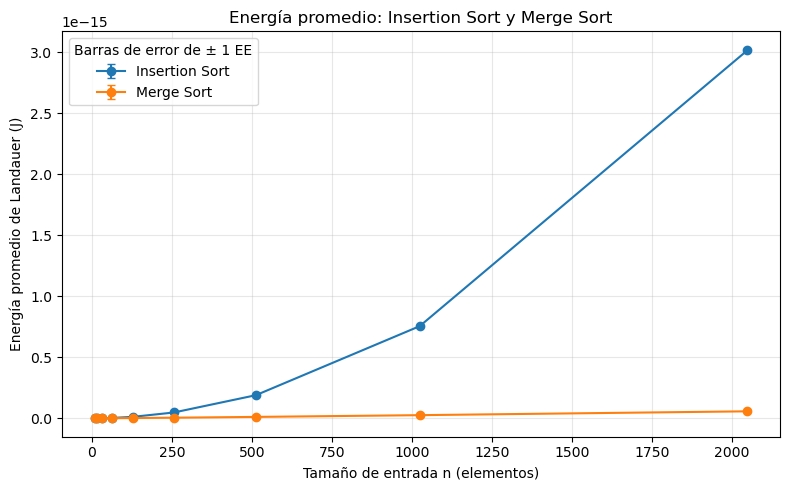

In [34]:
# 7.1. Comparaciones energéticas en escala lineal y log-log
def format_n_axis(ax):
    """Configura el eje de tamaños en escala logarítmica de base dos.

    Args:
        ax: Ejes de Matplotlib que se van a configurar.
    """
    ax.set_xscale("log", base=2)
    ax.set_xticks(N_VALUES, labels=[str(n) for n in N_VALUES])
    ax.set_xlabel("Tamaño de entrada n (elementos)")
    ax.grid(True, alpha=0.3)


COLORS = dict(
    zip(ALGORITHMS, ("tab:blue", "tab:orange", "tab:green", "tab:red"))
)
comparisons = (
    (
        "Energía promedio: Insertion Sort y Merge Sort",
        ("Insertion Sort", "Merge Sort"),
        False,
    ),
    (
        "Energía promedio: Merge Sort, Quick Sort y Heap Sort",
        ("Merge Sort", "Quick Sort", "Heap Sort"),
        False,
    ),
    (
        "Energía promedio de los cuatro algoritmos (log-log)",
        tuple(ALGORITHMS),
        True,
    ),
)


def plot_energy(title, names, log_scale):
    """Grafica las medias de los algoritmos elegidos con barras de EE.

    Args:
        title: Título de la gráfica.
        names: Nombres de los algoritmos que se van a mostrar.
        log_scale: Indica si se usan dos ejes logarítmicos.
    """
    fig, ax = plt.subplots(figsize=(8, 5))
    for name in names:
        group = summary[summary["algorithm"] == name].sort_values("n")
        ax.errorbar(
            group["n"],
            group["mean_energy"],
            yerr=group["se_energy"],
            marker="o",
            capsize=3,
            color=COLORS[name],
            label=name,
        )
    if log_scale:
        format_n_axis(ax)
        ax.set_yscale("log")
    ax.set_xlabel("Tamaño de entrada n (elementos)")
    ax.set_ylabel("Energía promedio de Landauer (J)")
    ax.set_title(title)
    ax.legend(title="Barras de error de ± 1 EE")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()


plot_energy(*comparisons[0])


**Interpretación.** A $n=2048$, Insertion Sort promedia 1050606,48
comparaciones y Merge Sort 19938,38. La diferencia de
comparaciones explica la separación energética de las curvas, porque cada
descarte añade el mismo $q_L$. El crecimiento de Insertion Sort es coherente
con el término cuadrático de su número esperado de inversiones.

### 7.2. Merge Sort, Quick Sort y Heap Sort en escala lineal

Esta figura usa una escala lineal centrada en las tres series de menor energía
en los tamaños grandes. Así se puede comparar el costo de fusionar bloques,
particionar con un pivote y mantener un montículo.

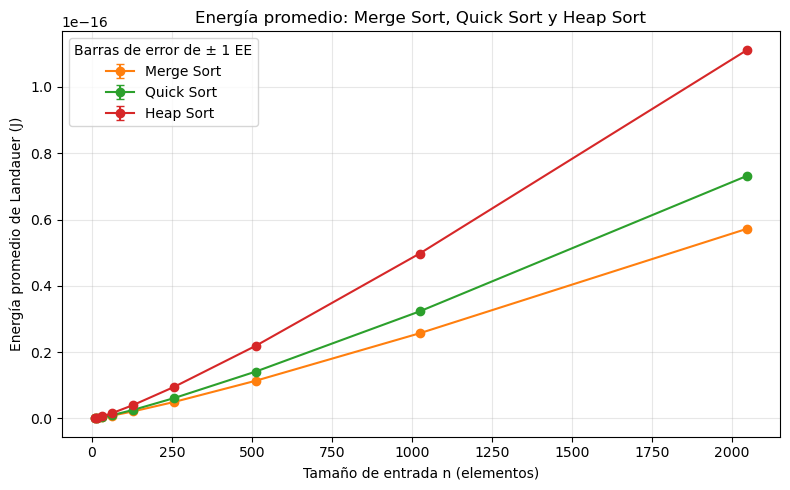

In [35]:
plot_energy(*comparisons[1])


**Interpretación.** A $n=2048$, Merge Sort, Quick Sort y Heap Sort promedian, respectivamente,
$5{,}72\times10^{-17}$, $7{,}32\times10^{-17}$ y $1{,}11\times10^{-16}$ J.
Merge Sort deja de comparar cuando agota una mitad. Quick Sort compara
cada clave del intervalo con el pivote y el balance determina cuántas
particiones posteriores serán necesarias. Heap Sort compara candidatos
durante la construcción y las restauraciones del montículo. El número de
resultados descartados explica el orden de estas tres medias.

### 7.3. Comparación de los cuatro algoritmos en escala log-log

Ambos ejes son logarítmicos. La figura reúne los cuatro algoritmos y conserva
sus colores y barras de ±1 EE. Se ajusta una recta a los logaritmos de las medias
y de los tamaños para describir la pendiente sobre el intervalo simulado.

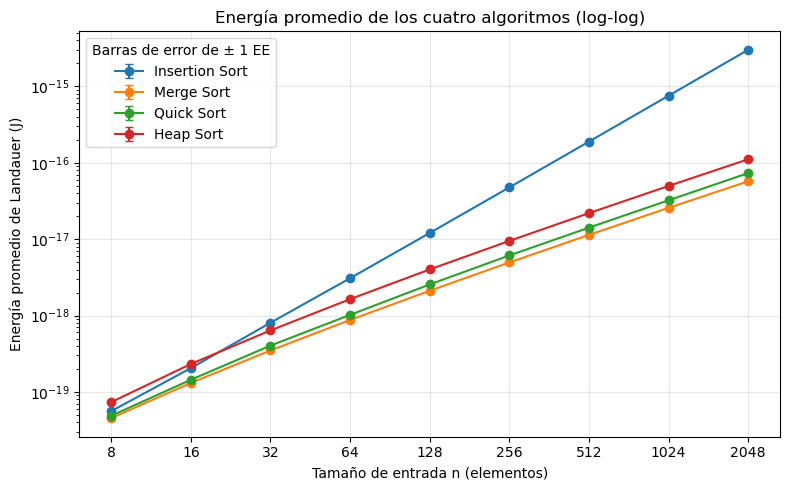

,Pendiente log-log
Insertion Sort,1.969
Merge Sort,1.277
Quick Sort,1.308
Heap Sort,1.304


In [36]:
plot_energy(*comparisons[2])

log_slopes = {}
for name in ALGORITHMS:
    group = summary[summary["algorithm"] == name]
    log_slopes[name] = np.polyfit(
        np.log(group["n"]), np.log(group["mean_energy"]), 1
    )[0]
display(
    pd.Series(log_slopes, name="Pendiente log-log")
    .to_frame()
    .style.format("{:.3f}")
)


**Interpretación.** Las pendientes ajustadas entre 8 y 2048 elementos son Insertion Sort (1,969), Merge Sort (1,277), Quick Sort (1,308), Heap Sort (1,304).
Describen el crecimiento en el intervalo observado. La pendiente de
$\log(n\log n)$ frente a $\log n$ supera uno para tamaños finitos y varía
con $n$. También influyen los términos de menor orden. Por eso, la cercanía
entre las tres pendientes menores es compatible con el comportamiento
lineal-logarítmico, mientras que la de Insertion Sort se aproxima a dos.
La validación de la sección 8 contrasta estas lecturas con el conteo.

## 8. Validación

### 8.1. Validación analítica de Insertion Sort

En una permutación uniforme, cada par de claves tiene probabilidad $1/2$ de
estar invertido. Cada inversión aporta una comparación exitosa seguida de
un intercambio. En la etapa que inserta la $i$-ésima clave, con $i=2,\ldots,n$,
hay una comparación adicional de parada salvo si la clave es el mínimo del
prefijo, lo que sucede con probabilidad $1/i$. Así,

$$
\mathbb E[C_n]=\frac{n(n-1)}{4}+n-H_n,\qquad
H_n=\sum_{i=1}^n\frac1i.
$$

El producto por $q_L$ da la referencia energética. La tabla compara esa
referencia con la media simulada en porcentaje y en unidades de EE.

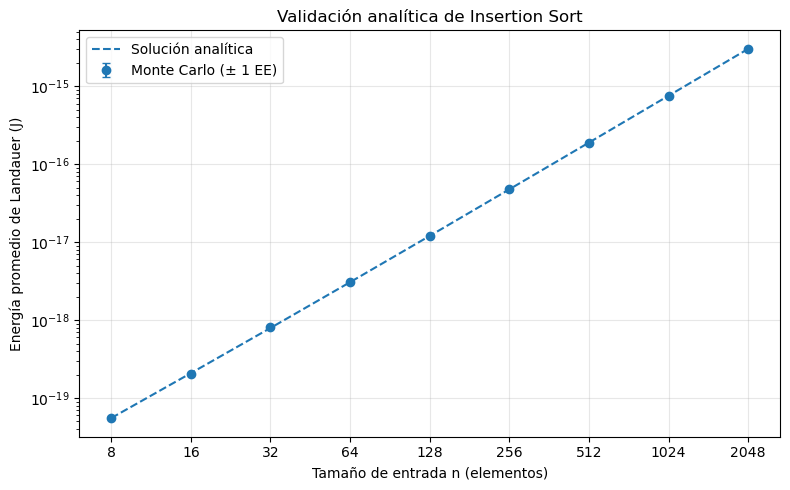

,n,Simulación (J),Teoría (J),Error relativo (%),Diferencia / EE
1,8,5.60128e-20,5.53586e-20,1.182,0.66
5,16,2.04902e-19,2.08488e-19,1.720,1.13
9,32,8.04621e-19,7.92222e-19,1.565,1.36
13,64,3.08263e-18,3.06407e-18,0.606,0.69
17,128,1.20577e-17,1.20195e-17,0.317,0.56
21,256,4.76475e-17,4.75718e-17,0.159,0.37
25,512,1.89354e-16,1.89235e-16,0.062,0.23
29,1024,7.55226e-16,7.54793e-16,0.057,0.30
33,2048,3.01627e-15,3.01483e-15,0.048,0.31


In [37]:
# 8.1. Comparación analítica de Insertion Sort
def harmonic_number(n):
    """Suma los recíprocos de los primeros enteros positivos.

    Args:
        n: Último entero incluido en la suma.

    Returns:
        Número armónico de orden n.
    """
    return math.fsum(1 / i for i in range(1, n + 1))


def insertion_expected_comparisons(n):
    """Calcula la media teórica de comparaciones de Insertion Sort.

    Args:
        n: Número de claves distintas en la permutación uniforme.

    Returns:
        Número esperado de comparaciones.
    """
    return n * (n - 1) / 4 + n - harmonic_number(n)


validation_i = (
    summary[summary["algorithm"] == "Insertion Sort"].copy().sort_values("n")
)
validation_i["theoretical_bits"] = validation_i["n"].map(
    insertion_expected_comparisons
)
validation_i["theoretical_energy"] = calculate_energy(
    validation_i["theoretical_bits"]
)
validation_i["relative_error_pct"] = 100 * (
    (validation_i["mean_energy"] - validation_i["theoretical_energy"]).abs()
    / validation_i["theoretical_energy"]
)
validation_i["difference_in_se"] = (
    validation_i["mean_energy"] - validation_i["theoretical_energy"]
).abs() / validation_i["se_energy"].replace(0, np.nan)
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    validation_i["n"],
    validation_i["mean_energy"],
    yerr=validation_i["se_energy"],
    fmt="o",
    color=COLORS["Insertion Sort"],
    capsize=3,
    label="Monte Carlo (± 1 EE)",
)
ax.plot(
    validation_i["n"],
    validation_i["theoretical_energy"],
    linestyle="--",
    label="Solución analítica",
)
format_n_axis(ax)
ax.set_yscale("log")
ax.set_ylabel("Energía promedio de Landauer (J)")
ax.set_title("Validación analítica de Insertion Sort")
ax.legend()
fig.tight_layout()
plt.show()
display(
    validation_i[
        [
            "n",
            "mean_energy",
            "theoretical_energy",
            "relative_error_pct",
            "difference_in_se",
        ]
    ]
    .rename(
        columns={
            "mean_energy": "Simulación (J)",
            "theoretical_energy": "Teoría (J)",
            "relative_error_pct": "Error relativo (%)",
            "difference_in_se": "Diferencia / EE",
        }
    )
    .style.format(
        {
            "Simulación (J)": "{:.5e}",
            "Teoría (J)": "{:.5e}",
            "Error relativo (%)": "{:.3f}",
            "Diferencia / EE": "{:.2f}",
        }
    )
)


**Interpretación.** El error relativo máximo es 1,72 % para
$n=16$. A $n=2048$ es 0,048 %. Estas
discrepancias cuantifican la diferencia entre el promedio de 100 permutaciones
y la esperanza analítica. El EE ayuda a interpretarlas junto con la variación
entre permutaciones. Un error porcentual pequeño por sí solo no informa
cuántos EE separan la media simulada de la esperanza.

### 8.2. Costo normalizado de Merge Sort

El teorema 6.2 de Demaine et al. (2016) demuestra que el ordenamiento por
comparaciones que pierde el orden original puede realizarse en tiempo y
energía $\Theta(n\log_2 n)$ y espacio $\Theta(n)$ en su modelo. La construcción
de Merge Sort mueve claves hacia posiciones vacías mediante intercambios y
carga el descarte de los resultados de comparación. Aquí las fusiones son
iterativas, usan un bloque auxiliar de $n$ palabras y aplican la misma regla
de costo a las comparaciones. La figura examina $\overline B/(n\log_2 n)$
para contrastar el comportamiento observado con ese orden de crecimiento.

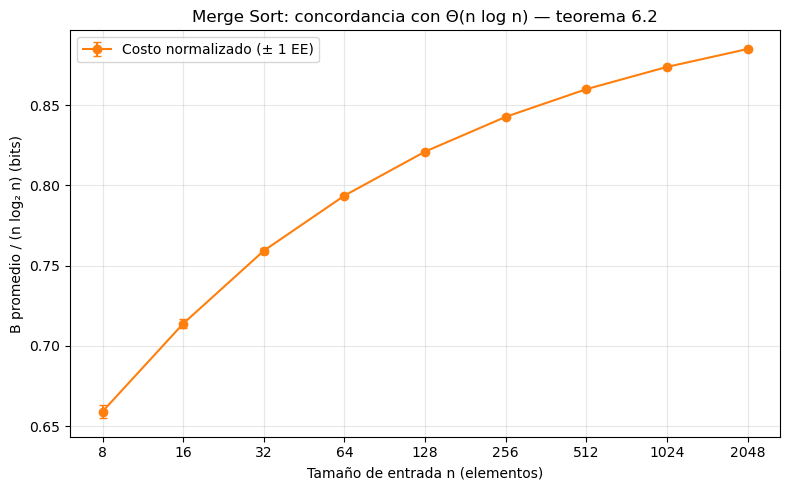

,n,normalized_bits,normalized_se
2,8,0.65917,0.00420
6,16,0.71391,0.00263
10,32,0.75938,0.00195
14,64,0.79370,0.00104
18,128,0.82112,0.00072
22,256,0.84279,0.00043
26,512,0.86003,0.00026
30,1024,0.87388,0.00016
34,2048,0.88505,0.00012


In [38]:
# 8.2. Comparación con el teorema 6.2
validation_m = (
    summary[summary["algorithm"] == "Merge Sort"].copy().sort_values("n")
)
normalizer = validation_m["n"] * np.log2(validation_m["n"])
validation_m["normalized_bits"] = validation_m["mean_bits"] / normalizer
validation_m["normalized_se"] = (validation_m["se_energy"] / q_L) / normalizer
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    validation_m["n"],
    validation_m["normalized_bits"],
    yerr=validation_m["normalized_se"],
    marker="o",
    color=COLORS["Merge Sort"],
    capsize=3,
    label="Costo normalizado (± 1 EE)",
)
format_n_axis(ax)
ax.set_ylabel("B promedio / (n log₂ n) (bits)")
ax.set_title("Merge Sort: concordancia con Θ(n log n) — teorema 6.2")
ax.legend()
fig.tight_layout()
plt.show()
display(
    validation_m[["n", "normalized_bits", "normalized_se"]].style.format(
        {"normalized_bits": "{:.5f}", "normalized_se": "{:.5f}"}
    )
)


**Interpretación.** El cociente pasa de 0,659 a 0,885
entre los extremos simulados. Su magnitud acotada en estos tamaños concuerda
con la escala lineal-logarítmica esperada. La justificación asintótica
proviene del conteo de comparaciones por nivel y del teorema 6.2.

### 8.3. Costo normalizado de Quick Sort y Heap Sort

Se divide el promedio de comparaciones por $n\log_2 n$ en cada tamaño. Como
cada comparación aporta un bit, el cociente también expresa el costo en bits
normalizado. Las dos columnas permiten comparar los algoritmos bajo la misma
regla y las mismas permutaciones.

In [39]:
quick_heap = summary[
    summary["algorithm"].isin(("Quick Sort", "Heap Sort"))
].copy()
quick_heap["normalized_comparisons"] = quick_heap["mean_comparisons"] / (
    quick_heap["n"] * np.log2(quick_heap["n"])
)
display(
    quick_heap.pivot(
        index="n", columns="algorithm", values="normalized_comparisons"
    ).style.format("{:.4f}")
)


algorithm,Heap Sort,Quick Sort
n,,
8,1.0667,0.7071
16,1.2634,0.7845
32,1.3905,0.8794
64,1.4868,0.9259
128,1.5603,0.9926
256,1.6140,1.0410
512,1.6567,1.0692
1024,1.6919,1.0985
2048,1.7191,1.1320


**Interpretación.** A $n=2048$, las comparaciones normalizadas son 1,132 para
Quick Sort y 1,719 para Heap Sort. Sobre permutaciones uniformes
de claves distintas, el rango del pivote central es uniforme dentro del
subproblema, y el costo esperado de las particiones es de orden
$\Theta(n\log_2 n)$. Una entrada que sitúa sucesivamente el mínimo o el máximo como pivote permite
un peor caso cuadrático. En Heap Sort, la construcción cuesta orden lineal
y cada extracción puede bajar a lo sumo una altura logarítmica. La tabla
describe los promedios simulados bajo estas estrategias.

### 8.4. Referencia informacional

El teorema 6.1 de Demaine et al. (2016) establece una cota energética
$\Omega(\log_2(n!))$ para un ordenamiento por comparaciones que destruye el
orden de su entrada. Con $n$ claves distintas hay $n!$ órdenes posibles.
Si esos órdenes son equiprobables y el estado final conserva solo el arreglo
ordenado, su pérdida de entropía informacional es $\log_2(n!)$ bits. Al
multiplicarla por $q_L$ se obtiene la referencia de la figura,
$k_B T\ln(n!)$. El argumento requiere perder la información del orden
original. Si se guarda una copia o un historial suficiente para recuperarlo,
cambia el estado final y esta cota no se traslada directamente al proceso.

La comparación se refiere a la memoria ordenada de cada ejecución, cuyo
bloque auxiliar acaba vacío. Las copias que conserva el programa anfitrión
para repetir los ensayos quedan fuera de esa contabilidad.

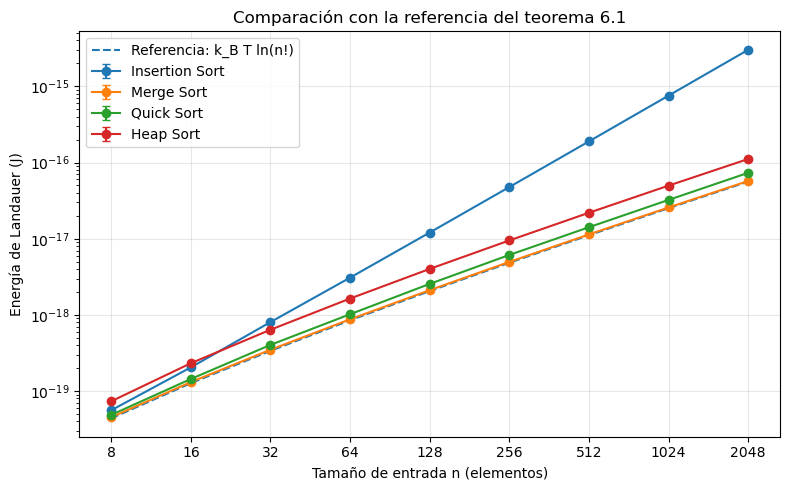

,n,Algoritmo,Promedio (J),Referencia (J),Promedio / referencia
0,8,Heap Sort,7.3497e-20,4.3924e-20,1.673
1,8,Insertion Sort,5.6013e-20,4.3924e-20,1.275
2,8,Merge Sort,4.5419e-20,4.3924e-20,1.034
3,8,Quick Sort,4.8721e-20,4.3924e-20,1.109
4,16,Heap Sort,2.3215e-19,1.2704e-19,1.827
5,16,Insertion Sort,2.0490e-19,1.2704e-19,1.613
6,16,Merge Sort,1.3118e-19,1.2704e-19,1.033
7,16,Quick Sort,1.4415e-19,1.2704e-19,1.135
8,32,Heap Sort,6.3874e-19,3.3781e-19,1.891
9,32,Insertion Sort,8.0462e-19,3.3781e-19,2.382


In [40]:
# 8.4. Comparación con la referencia informacional del teorema 6.1
def lower_bound_energy(n):
    """Convierte la entropía de los órdenes posibles a joules.

    Args:
        n: Número de claves distintas.

    Returns:
        Referencia informacional para un orden inicial uniforme.
    """
    # lgamma(n + 1) = ln(n!) sin calcular directamente el factorial.
    return k_B * T * math.lgamma(n + 1)


bound = pd.DataFrame({"n": N_VALUES})
bound["lower_bound"] = bound["n"].map(lower_bound_energy)
comparison_bound = summary.merge(bound, on="n")
comparison_bound["ratio_to_bound"] = (
    comparison_bound["mean_energy"] / comparison_bound["lower_bound"]
)
fig, ax = plt.subplots(figsize=(8, 5))
for name in ALGORITHMS:
    group = comparison_bound[
        comparison_bound["algorithm"] == name
    ].sort_values("n")
    ax.errorbar(
        group["n"],
        group["mean_energy"],
        yerr=group["se_energy"],
        marker="o",
        capsize=3,
        color=COLORS[name],
        label=name,
    )
ax.plot(
    bound["n"],
    bound["lower_bound"],
    linestyle="--",
    label="Referencia: k_B T ln(n!)",
)
format_n_axis(ax)
ax.set_yscale("log")
ax.set_ylabel("Energía de Landauer (J)")
ax.set_title("Comparación con la referencia del teorema 6.1")
ax.legend()
fig.tight_layout()
plt.show()
display(
    comparison_bound[
        ["n", "algorithm", "mean_energy", "lower_bound", "ratio_to_bound"]
    ]
    .rename(
        columns={
            "algorithm": "Algoritmo",
            "mean_energy": "Promedio (J)",
            "lower_bound": "Referencia (J)",
            "ratio_to_bound": "Promedio / referencia",
        }
    )
    .style.format(
        {
            "Promedio (J)": "{:.4e}",
            "Referencia (J)": "{:.4e}",
            "Promedio / referencia": "{:.3f}",
        }
    )
)


**Interpretación.** En las 36 combinaciones de tamaño y algoritmo, la media dividida por la
referencia es al menos 1,018. Eso es coherente con la pérdida del
orden original en la memoria modelada. El cociente mide cuánto supera el
conteo de descartes a esa referencia para estas entradas. La distancia
respecto a uno depende del algoritmo y del tamaño.

### 8.5. Convergencia de Monte Carlo

Para cada algoritmo se recalculan la media acumulada y su EE con las fórmulas
de la sección 5, usando los primeros ensayos de la secuencia para 128 elementos.
El EE empieza a partir de dos observaciones. Se muestra la trayectoria de la
media con su banda de incertidumbre y se comparan los EE acumulados. La curva
de Insertion Sort incluye su valor analítico como referencia adicional.

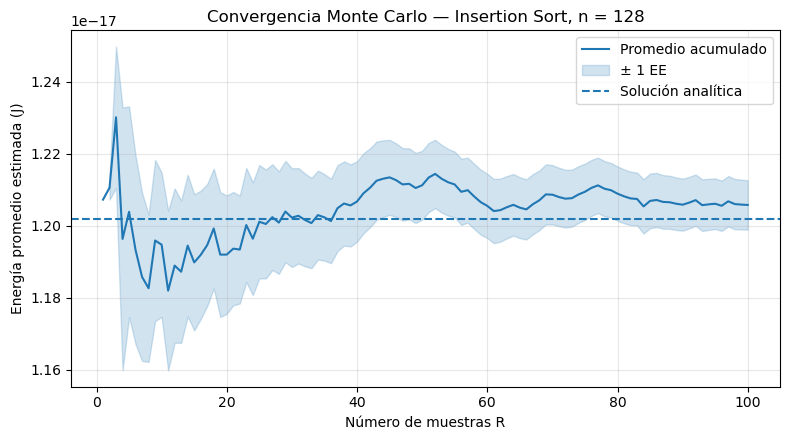

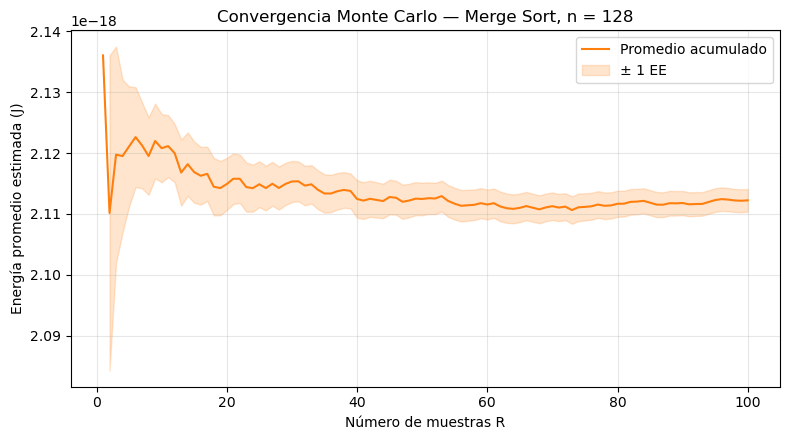

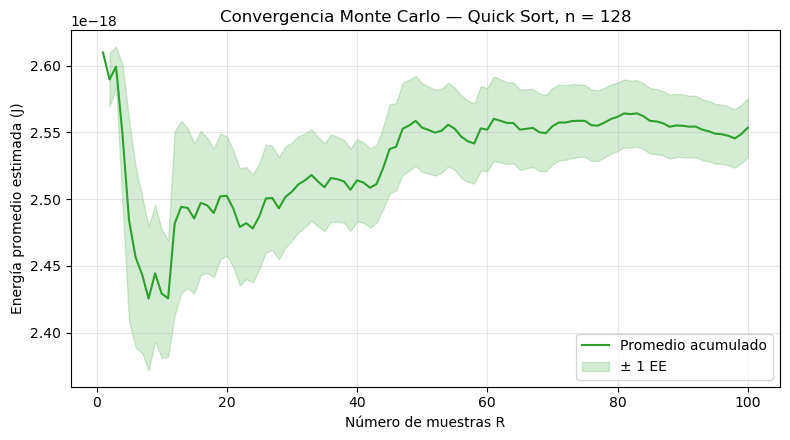

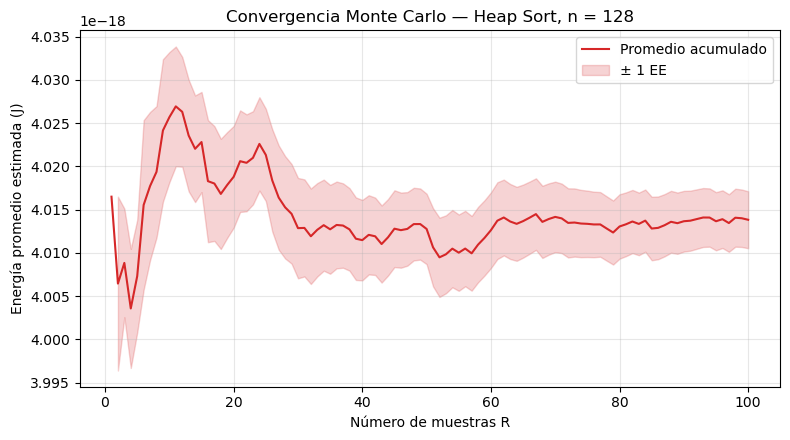

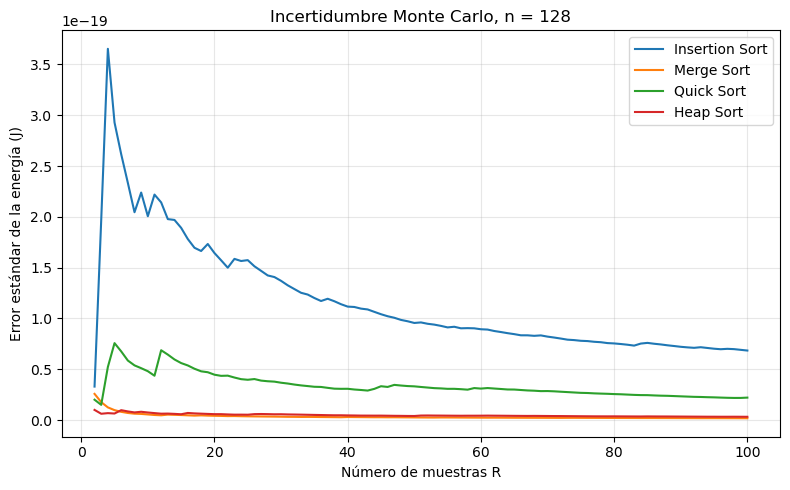

,algorithm,repetition,running_mean,running_se,relative_se_pct
1999,Heap Sort,100,4.0138e-18,3.2907e-21,0.082
1996,Insertion Sort,100,1.2058e-17,6.8470e-20,0.568
1997,Merge Sort,100,2.1122e-18,1.8557e-21,0.088
1998,Quick Sort,100,2.5534e-18,2.2158e-20,0.868


In [41]:
# 8.5. Análisis de convergencia de Monte Carlo
n_convergence = 128 if 128 in N_VALUES else N_VALUES[len(N_VALUES) // 2]
convergence = (
    results[results["n"] == n_convergence]
    .copy()
    .sort_values(["algorithm", "repetition"])
)
convergence["running_mean"] = convergence.groupby("algorithm")[
    "energy"
].transform(lambda x: x.expanding().mean())
convergence["running_se"] = convergence.groupby("algorithm")[
    "energy"
].transform(
    lambda x: (
        x.expanding(min_periods=2).std() / np.sqrt(np.arange(1, len(x) + 1))
    )
)

for name in ALGORITHMS:
    group = convergence[convergence["algorithm"] == name]
    r = group["repetition"].to_numpy()
    mean = group["running_mean"].to_numpy()
    se = group["running_se"].to_numpy()
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(r, mean, color=COLORS[name], label="Promedio acumulado")
    ax.fill_between(
        r, mean - se, mean + se, alpha=0.2, color=COLORS[name], label="± 1 EE"
    )
    if name == "Insertion Sort":
        ax.axhline(
            calculate_energy(insertion_expected_comparisons(n_convergence)),
            linestyle="--",
            label="Solución analítica",
        )
    ax.set_xlabel("Número de muestras R")
    ax.set_ylabel("Energía promedio estimada (J)")
    ax.set_title(f"Convergencia Monte Carlo — {name}, n = {n_convergence}")
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for name in ALGORITHMS:
    group = convergence[convergence["algorithm"] == name]
    ax.plot(
        group["repetition"],
        group["running_se"],
        color=COLORS[name],
        label=name,
    )
ax.set_xlabel("Número de muestras R")
ax.set_ylabel("Error estándar de la energía (J)")
ax.set_title(f"Incertidumbre Monte Carlo, n = {n_convergence}")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

final_precision = convergence.groupby("algorithm").tail(1).copy()
final_precision["relative_se_pct"] = (
    100 * final_precision["running_se"] / final_precision["running_mean"]
)
display(
    final_precision[
        [
            "algorithm",
            "repetition",
            "running_mean",
            "running_se",
            "relative_se_pct",
        ]
    ].style.format(
        {
            "running_mean": "{:.4e}",
            "running_se": "{:.4e}",
            "relative_se_pct": "{:.3f}",
        }
    )
)


**Interpretación.** En $n=128$, el EE relativo tras 100 ensayos es Insertion Sort (0,568 %), Merge Sort (0,088 %), Quick Sort (0,868 %), Heap Sort (0,082 %). Al crecer el
número de ensayos, la media acumulada puede seguir oscilando y el EE cambia
tanto por el denominador $\sqrt R$ como por la desviación muestral. La ley
de los grandes números explica la convergencia de la media para ensayos
independientes sobre la misma distribución. Estas curvas documentan la
precisión de las estimaciones para $n=128$.

La validación analítica, las normalizaciones y la referencia informacional se complementan: cada una compara una propiedad distinta del costo modelado.

## 9. Limitaciones

El modelo contabiliza las comparaciones entre claves y distingue los intercambios reversibles de las sobrescrituras irreversibles. El control de índices, la pila de intervalos de Quick Sort y los contadores quedan fuera del costo energético modelado. La energía calculada representa la contribución mínima asociada con los bits contabilizados a 300 K. Las permutaciones con claves distintas describen el escenario experimental; las pruebas con empates comprueban corrección, pero no caracterizan su costo promedio.

Los ceros representan palabras auxiliares vacías en la implementación.
La conversión a joules depende de una temperatura fija y del supuesto de
borrado ideal por bit contabilizado. El coste de un procesador real también
incluye conmutación, tráfico de memoria, fugas, control y refrigeración.
Los resultados tampoco caracterizan distribuciones con empates ni entradas
seleccionadas para provocar particiones desfavorables.


## 10. Conclusiones y conexión con ISC

El algoritmo con menor energía media a $n=8$ es Merge Sort.
A $n=2048$, el orden de menor a mayor es Merge Sort, Quick Sort, Heap Sort, Insertion Sort. Insertion
Sort crece más rápido porque su número esperado de comparaciones contiene
un término cuadrático. Entre los otros tres, las fusiones, las particiones
y las restauraciones producen distintos números de comparaciones aunque
sus costos promedio sean compatibles con un crecimiento lineal-logarítmico.
Bajo las convenciones del ensayo, $E=Cq_L$ para los cuatro algoritmos,
porque cada comparación descarta un resultado y los intercambios conservan
las claves. El orden obtenido responde al costo de información del modelo
y al escenario de permutaciones estudiado.

En Ingeniería de Sistemas y Computación, este contraste motiva evaluar tiempo,
espacio e información descartada como dimensiones distintas. Merge Sort usa
un bloque auxiliar para trasladar claves sin sobrescribir valores útiles. Heap
Sort realiza el ordenamiento con intercambios en el arreglo y, para estas
entradas, descarta más resultados de comparación. En una implementación
reversible se podría conservar un historial y deshacer parte del cómputo para
limpiar el estado auxiliar. Ese diseño intercambia memoria y operaciones
adicionales por la posibilidad de reducir los borrados. Su beneficio en un
sistema físico requeriría medir la energía de la implementación completa.


## 11. Referencias y declaración de uso de IA

### 11.1. Referencias bibliográficas

- Demaine, E. D., Lynch, J., Mirano, G. J. y Tyagi, N. (2016).
  *Energy-Efficient Algorithms*. arXiv:1605.08448.
  [Artículo en arXiv](https://arxiv.org/abs/1605.08448).
- van Rossum, G., Warsaw, B. y Coghlan, N. (2001).
  *PEP 8 — Style Guide for Python Code*. Python Software Foundation.
  [Guía de estilo de Python](https://peps.python.org/pep-0008/).

### 11.2. Declaración de uso de Inteligencia artificial 
Se utilizaron herramientas de inteligencia artificial de OpenAI y DeepSeek como apoyo en la implementación y revisión del código, las pruebas de funcionamiento, la verificación de resultados y la organización del ensayo computacional.
